# Paso 2 — EFA por bloques temáticos

**Input:** `dataset_filtrado.csv` (592 columnas, 6,968 estudiantes)  
**Output:** `dataset_efa_items_seleccionados.csv` — ítems con carga factorial ≥ 0.40  

**Flujo:**
1. Detectar prefijos y proponer bloques automáticamente
2. Confirmar/ajustar bloques
3. Imputar missing por bloque
4. Aplicar EFA por bloque
5. Seleccionar ítems con carga ≥ 0.40
6. Guardar dataset final para IRT y LCA

## 0. Librerías

Necesitas instalar y updatear cotnenedor de docker `factor_analyzer` si no lo tienes:
```
pip install factor_analyzer
```

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity

# Umbral de carga factorial para retener un ítem
UMBRAL_CARGA = 0.40

print("Librerías cargadas.")

Librerías cargadas.


## 1. Cargar dataset filtrado

In [38]:
df = pd.read_csv("/workspace/data/output_rural/dataset_filtrado.csv", low_memory=False)
print(f"Dataset cargado: {df.shape[0]:,} filas × {df.shape[1]:,} columnas")

Dataset cargado: 3,720 filas × 573 columnas


## 2. Detectar prefijos automáticamente

PISA nombra sus variables con prefijos de 2–4 caracteres que indican el cuestionario de origen.  
Esta celda los detecta y muestra el conteo para que puedas decidir cómo agrupar.

In [39]:
def extraer_prefijo(nombre, largo=2):
    """Extrae los primeros `largo` caracteres alfabéticos del nombre de columna."""
    letras = ''.join([c for c in nombre if c.isalpha()])
    return letras[:largo].upper() if len(letras) >= largo else nombre.upper()[:largo]

# Probar con prefijos de 2 y 3 caracteres
for largo in [2, 3]:
    prefijos = pd.Series([extraer_prefijo(c, largo) for c in df.columns])
    conteo = prefijos.value_counts()
    print(f"\nPrefijos de {largo} caracteres ({len(conteo)} grupos):")
    print(conteo.to_string())


Prefijos de 2 caracteres (30 grupos):
SC    300
ST    136
FL     93
RS      4
MS      4
RC      3
MA      3
EF      2
PR      2
CO      2
SR      2
MC      2
VE      2
MI      2
GR      1
PA      1
RD      1
MP      1
IS      1
LA      1
RE      1
SK      1
TA      1
DU      1
FI      1
HI      1
UN      1
CL      1
CR      1
AB      1

Prefijos de 3 caracteres (38 grupos):
SCQ    296
STQ    129
FLQ     93
STD      7
RCO      3
EFF      2
COB      2
SRE      2
RSL      2
RST      2
MSI      2
MSL      2
VER      2
MIS      2
MAT      2
SCH      2
SCS      2
PRO      1
GRA      1
PAR      1
RDE      1
MPA      1
MCO      1
ISC      1
LAN      1
REP      1
SKI      1
TAR      1
DUR      1
FIS      1
HIS      1
UNI      1
PRI      1
MCL      1
CLS      1
CRE      1
MAC      1
ABG      1


## 3. Definir bloques temáticos

Basándote en los prefijos detectados arriba, define tus bloques.  
Cada bloque es una lista de prefijos que pertenecen al mismo cuestionario.

**Referencia de prefijos PISA estándar:**
- `ST` → Cuestionario del estudiante (Student)
- `SC` → Cuestionario de la escuela (School)
- `TC` → Cuestionario del docente (Teacher)
- `IC` → Cuestionario TIC / tecnología
- `PA` → Cuestionario de padres (Parents)
- `EC` → Cuestionario educativo complementario

Ajusta los nombres y prefijos según lo que viste en la celda anterior.

In [40]:
# ── AJUSTA ESTE DICCIONARIO según los prefijos que viste arriba ───────────────

BLOQUES_PREFIJOS = {
    "estudiante" : ["ST", "STQ", "STD"],

    "escuela"    : ["SC", "SCQ", "SCH", "SCS"],

    "docente"    : [],   # no aparece en tu dataset

    "tic"        : ["IC", "ISC"],

    "padres"     : ["PA", "PAR"],

    "finanzas"   : ["FL"], # FL comportamiento y Actitudes Financieras

    "otros"      : [
        "FL", "FLQ",
        "RS", "RSL", "RST",
        "MS", "MSI", "MSL",
        "RC", "RCO",
        "MA", "MAT", "MAC",
        "EF", "EFF",
        "PR", "PRO", "PRI",
        "CO", "COB",
        "SR", "SRE",
        "MC", "MCO", "MCL",
        "VE", "VER",
        "MI", "MIS",
        "GR", "GRA",
        "RD", "RDE",
        "MP", "MPA",
        "IS",
        "LA", "LAN",
        "RE", "REP",
        "SK", "SKI",
        "TA", "TAR",
        "EX", "EXP",
        "DU", "DUR",
        "SI", "SIS",
        "FI", "FIS",
        "HI", "HIS",
        "UN", "UNI",
        "CL", "CLS",
        "CR", "CRE",
        "AB", "ABG"
    ]
}
# ─────────────────────────────────────────────────────────────────────────────

# Asignar cada columna a su bloque
def asignar_bloque(nombre, bloques_dict, largo=2):
    pref = extraer_prefijo(nombre, largo)
    for bloque, prefijos in bloques_dict.items():
        if pref in [p.upper() for p in prefijos]:
            return bloque
    return "sin_clasificar"

bloque_por_col = {col: asignar_bloque(col, BLOQUES_PREFIJOS) for col in df.columns}
serie_bloques  = pd.Series(bloque_por_col)

print("Columnas por bloque:")
print(serie_bloques.value_counts().to_string())
print()
print("Nota: si 'sin_clasificar' tiene muchas columnas, revisa y agrega sus prefijos al diccionario.")

Columnas por bloque:
escuela       300
estudiante    136
finanzas       93
otros          43
padres          1

Nota: si 'sin_clasificar' tiene muchas columnas, revisa y agrega sus prefijos al diccionario.


Ajustes sobre el bloque escuela. Separarlo en 3 grupos.

In [41]:
# Subdivisión del bloque escuela por número de pregunta
cols_escuela = [c for c, b in bloque_por_col.items() if b == "escuela"]

def numero_pregunta_sc(nombre):
    """Extrae el número de pregunta de columnas tipo SC182Q06WA02 → 182"""
    import re
    match = re.search(r'SC(\d+)', nombre.upper())
    if match:
        return int(match.group(1))
    return 999

nums = sorted(set(numero_pregunta_sc(c) for c in cols_escuela))
print(f"Números de pregunta únicos en escuela ({len(nums)}):")
print(nums)

# Dividir en 3 sub-bloques por terciles de número de pregunta
tercil1 = np.percentile(nums, 33)
tercil2 = np.percentile(nums, 66)

def subbloque_escuela(nombre):
    n = numero_pregunta_sc(nombre)
    if n <= tercil1:
        return "escuela_a"
    elif n <= tercil2:
        return "escuela_b"
    else:
        return "escuela_c"

# Actualizar bloque_por_col para las columnas de escuela
for col in cols_escuela:
    bloque_por_col[col] = subbloque_escuela(col)

# Verificar tamaños
for sb in ["escuela_a", "escuela_b", "escuela_c"]:
    n = sum(1 for b in bloque_por_col.values() if b == sb)
    print(f"  {sb}: {n} columnas")

Números de pregunta únicos en escuela (60):
[1, 3, 4, 11, 12, 13, 14, 17, 18, 27, 32, 34, 35, 37, 42, 53, 61, 155, 168, 169, 170, 171, 172, 173, 174, 176, 177, 180, 182, 183, 184, 185, 187, 188, 189, 190, 192, 193, 195, 198, 200, 201, 202, 204, 205, 207, 208, 209, 210, 212, 214, 215, 216, 217, 220, 221, 222, 223, 224, 999]
  escuela_a: 99 columnas
  escuela_b: 92 columnas
  escuela_c: 109 columnas


## 4. Función de EFA para un bloque

In [42]:
def efa_bloque(df_bloque, nombre_bloque, umbral_carga=0.40, max_factores=10):
    """
    Aplica EFA a un bloque de columnas.
    Retorna:
        - items_seleccionados : lista de columnas con carga >= umbral en al menos un factor
        - df_cargas           : DataFrame de cargas factoriales
        - n_factores          : número de factores seleccionados por scree
    """
    print(f"\n{'═'*55}")
    print(f"  BLOQUE: {nombre_bloque.upper()} ({df_bloque.shape[1]} columnas)")
    print(f"{'═'*55}")

    # Imputar missing con la mediana de cada columna
    df_imp = df_bloque.apply(lambda col: col.fillna(col.median()))

    # Necesitamos al menos 5 columnas para EFA
    if df_imp.shape[1] < 5:
        print("  ✗ Bloque con menos de 5 columnas — omitido.")
        return [], pd.DataFrame(), 0

    # ── Prueba de adecuación muestral ─────────────────────────────────────────
    try:
        chi2, p_bartlett = calculate_bartlett_sphericity(df_imp)
        kmo_all, kmo_model = calculate_kmo(df_imp)
        print(f"  KMO          : {kmo_model:.3f}  "
              f"({'adecuado' if kmo_model >= 0.6 else 'bajo — interpretar con cautela'})")
        print(f"  Bartlett p   : {p_bartlett:.4f}  "
              f"({'significativo ✓' if p_bartlett < 0.05 else 'no significativo ✗'})")
        if kmo_model < 0.5:
            print("  ✗ KMO < 0.5 — bloque no apto para EFA. Omitido.")
            return [], pd.DataFrame(), 0
    except Exception as e:
        print(f"  ✗ Error en pruebas de adecuación: {e}. Omitido.")
        return [], pd.DataFrame(), 0

    # ── Scree plot para determinar número de factores ─────────────────────────
    try:
        fa_scree = FactorAnalyzer(n_factors=min(df_imp.shape[1]-1, max_factores),
                                   rotation=None)
        fa_scree.fit(df_imp)
        eigenvalores, _ = fa_scree.get_eigenvalues()
        n_factores = max(1, int((eigenvalores > 1).sum()))
        n_factores = min(n_factores, max_factores, df_imp.shape[1] - 1)
        print(f"  Factores seleccionados (eigenvalor > 1): {n_factores}")
    except Exception as e:
        print(f"  ✗ Error en scree: {e}. Omitido.")
        return [], pd.DataFrame(), 0

    # ── Scree plot visual ─────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot(range(1, len(eigenvalores)+1), eigenvalores, "o-", color="#4A90D9", markersize=5)
    ax.axhline(1, color="#E24B4A", linewidth=1, linestyle="--", label="Eigenvalor = 1")
    ax.axvline(n_factores, color="#27AE60", linewidth=1, linestyle=":",
               label=f"n_factores = {n_factores}")
    ax.set_title(f"Scree plot — bloque {nombre_bloque}")
    ax.set_xlabel("Factor")
    ax.set_ylabel("Eigenvalor")
    ax.legend(fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

    # ── EFA con rotación oblicua (oblimin) ────────────────────────────────────
    # Oblimin es preferible a varimax cuando se espera correlación entre factores
    try:
        fa = FactorAnalyzer(n_factors=n_factores, rotation="oblimin")
        fa.fit(df_imp)
    except Exception as e:
        print(f"  ✗ Error en EFA: {e}. Intentando sin rotación...")
        try:
            fa = FactorAnalyzer(n_factors=n_factores, rotation=None)
            fa.fit(df_imp)
        except Exception as e2:
            print(f"  ✗ Error sin rotación también: {e2}. Omitido.")
            return [], pd.DataFrame(), 0

    # ── Cargas factoriales ────────────────────────────────────────────────────
    cargas = fa.loadings_
    cols_factores = [f"F{i+1}_{nombre_bloque}" for i in range(n_factores)]
    df_cargas = pd.DataFrame(cargas, index=df_bloque.columns, columns=cols_factores)

    # Seleccionar ítems con carga >= umbral en al menos un factor
    carga_max = df_cargas.abs().max(axis=1)
    items_seleccionados = carga_max[carga_max >= umbral_carga].index.tolist()

    print(f"  Ítems con carga ≥ {umbral_carga}: {len(items_seleccionados)} / {df_bloque.shape[1]}")

    # Heatmap de cargas
    if len(items_seleccionados) > 0:
        altura = max(3, len(items_seleccionados) * 0.3)
        fig, ax = plt.subplots(figsize=(max(4, n_factores*1.5), altura))
        sns.heatmap(
            df_cargas.loc[items_seleccionados].round(2),
            annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1,
            linewidths=0.3, ax=ax, annot_kws={"size": 8}
        )
        ax.set_title(f"Cargas factoriales — bloque {nombre_bloque} (ítems seleccionados)")
        plt.tight_layout()
        plt.show()

    return items_seleccionados, df_cargas, n_factores

Ajustes para evitar factorizaciones demas en escuela:

In [43]:
# Límite de factores por bloque — ajustado para bloques grandes
MAX_FACTORES_POR_BLOQUE = {
    "estudiante" : 10,
    "escuela_a"  : 6, # reducido para evitar problemas de convergencia
    "escuela_b"  : 6, # reducido para evitar problemas de convergencia
    "escuela_c"  : 6, # reducido para evitar problemas de convergencia
    "docente"    : 10,
    "tic"        : 8,
    "padres"     : 2,
    "finanzas"   : 8,
    "otros"      : 5, # 13
}

## 5. Ejecutar EFA en todos los bloques


═══════════════════════════════════════════════════════
  BLOQUE: ESTUDIANTE (136 columnas)
═══════════════════════════════════════════════════════
  KMO          : 0.760  (adecuado)
  Bartlett p   : 0.0000  (significativo ✓)
  Factores seleccionados (eigenvalor > 1): 10


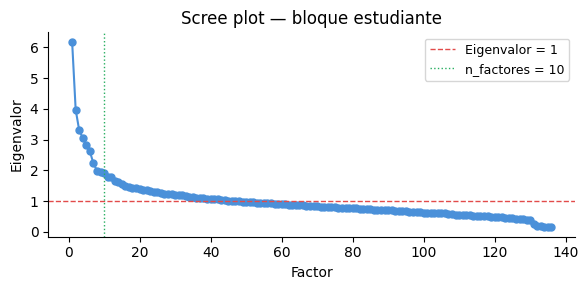

  Ítems con carga ≥ 0.4: 47 / 136


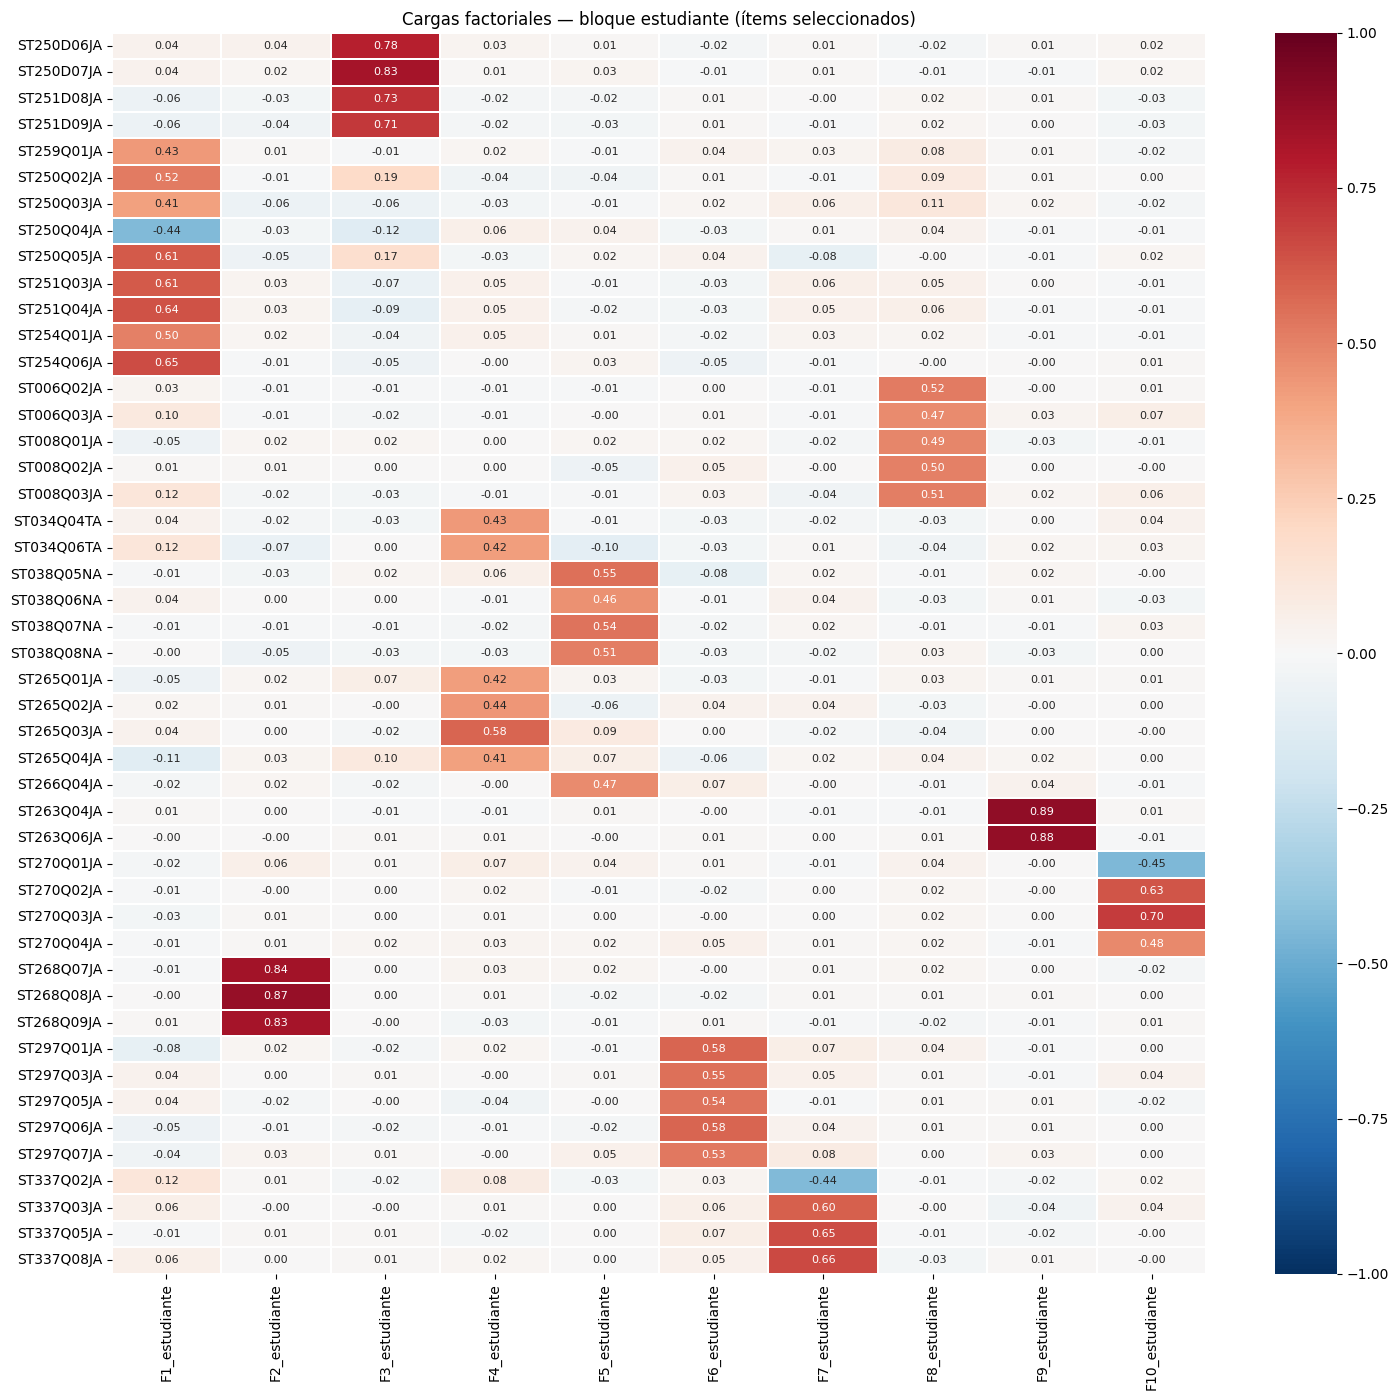


═══════════════════════════════════════════════════════
  BLOQUE: ESCUELA_A (99 columnas)
═══════════════════════════════════════════════════════
  KMO          : 0.485  (bajo — interpretar con cautela)
  Bartlett p   : 0.0000  (significativo ✓)
  ✗ KMO < 0.5 — bloque no apto para EFA. Omitido.

═══════════════════════════════════════════════════════
  BLOQUE: ESCUELA_B (92 columnas)
═══════════════════════════════════════════════════════
  KMO          : 0.546  (bajo — interpretar con cautela)
  Bartlett p   : 0.0000  (significativo ✓)
  Factores seleccionados (eigenvalor > 1): 6


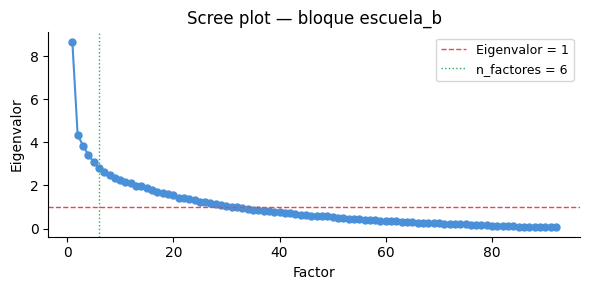

  Ítems con carga ≥ 0.4: 34 / 92


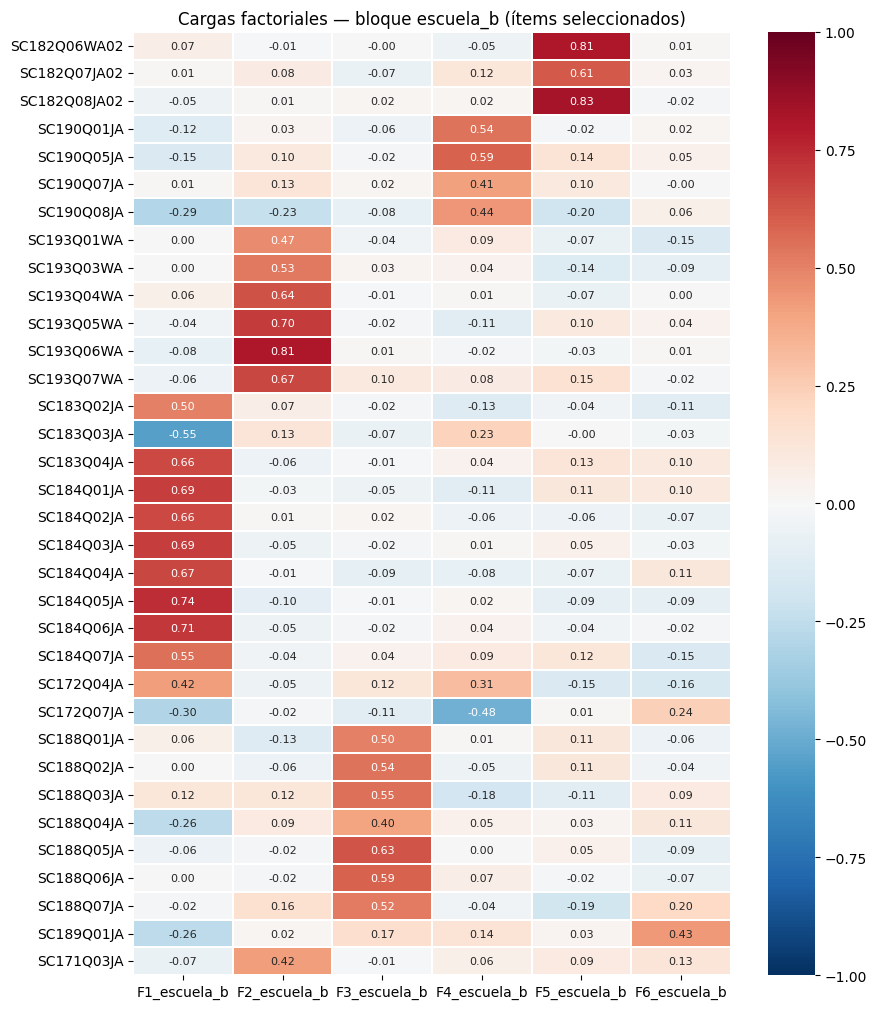


═══════════════════════════════════════════════════════
  BLOQUE: ESCUELA_C (109 columnas)
═══════════════════════════════════════════════════════
  KMO          : 0.557  (bajo — interpretar con cautela)
  Bartlett p   : 0.0000  (significativo ✓)
  Factores seleccionados (eigenvalor > 1): 6


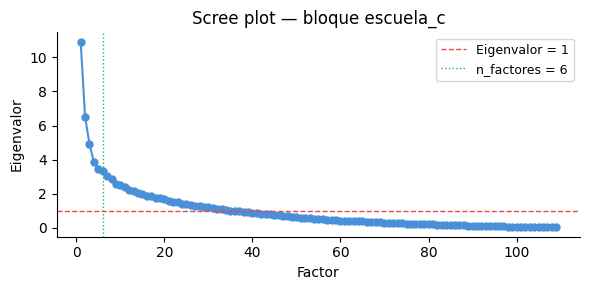

  Ítems con carga ≥ 0.4: 49 / 109


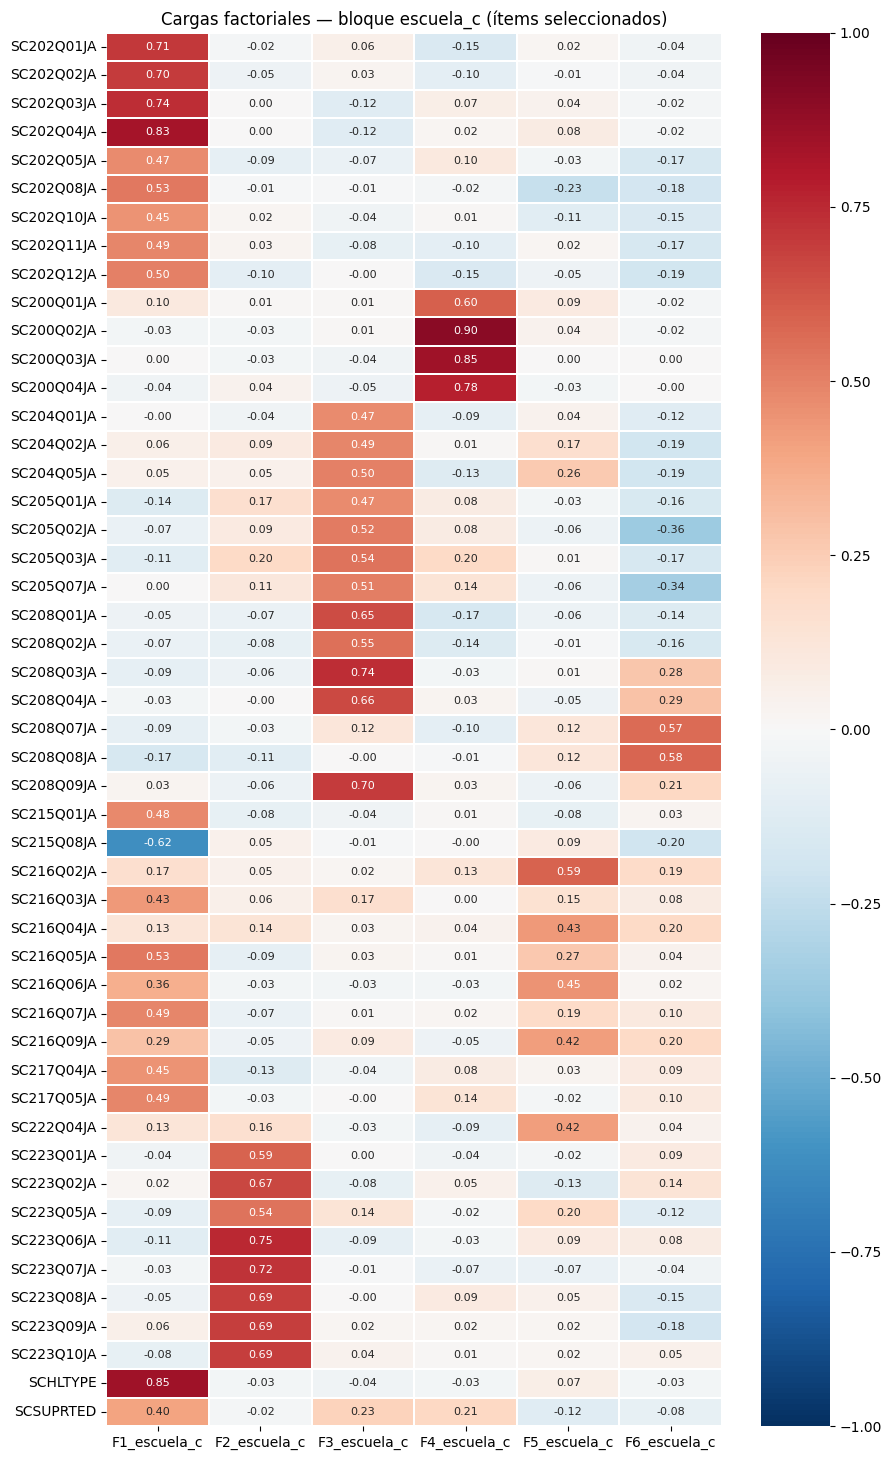


═══════════════════════════════════════════════════════
  BLOQUE: FINANZAS (93 columnas)
═══════════════════════════════════════════════════════
  KMO          : 0.895  (adecuado)
  Bartlett p   : 0.0000  (significativo ✓)
  Factores seleccionados (eigenvalor > 1): 8


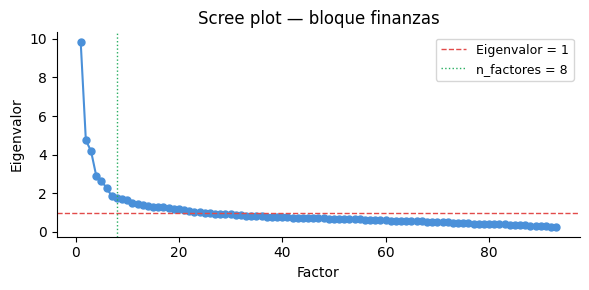

  Ítems con carga ≥ 0.4: 51 / 93


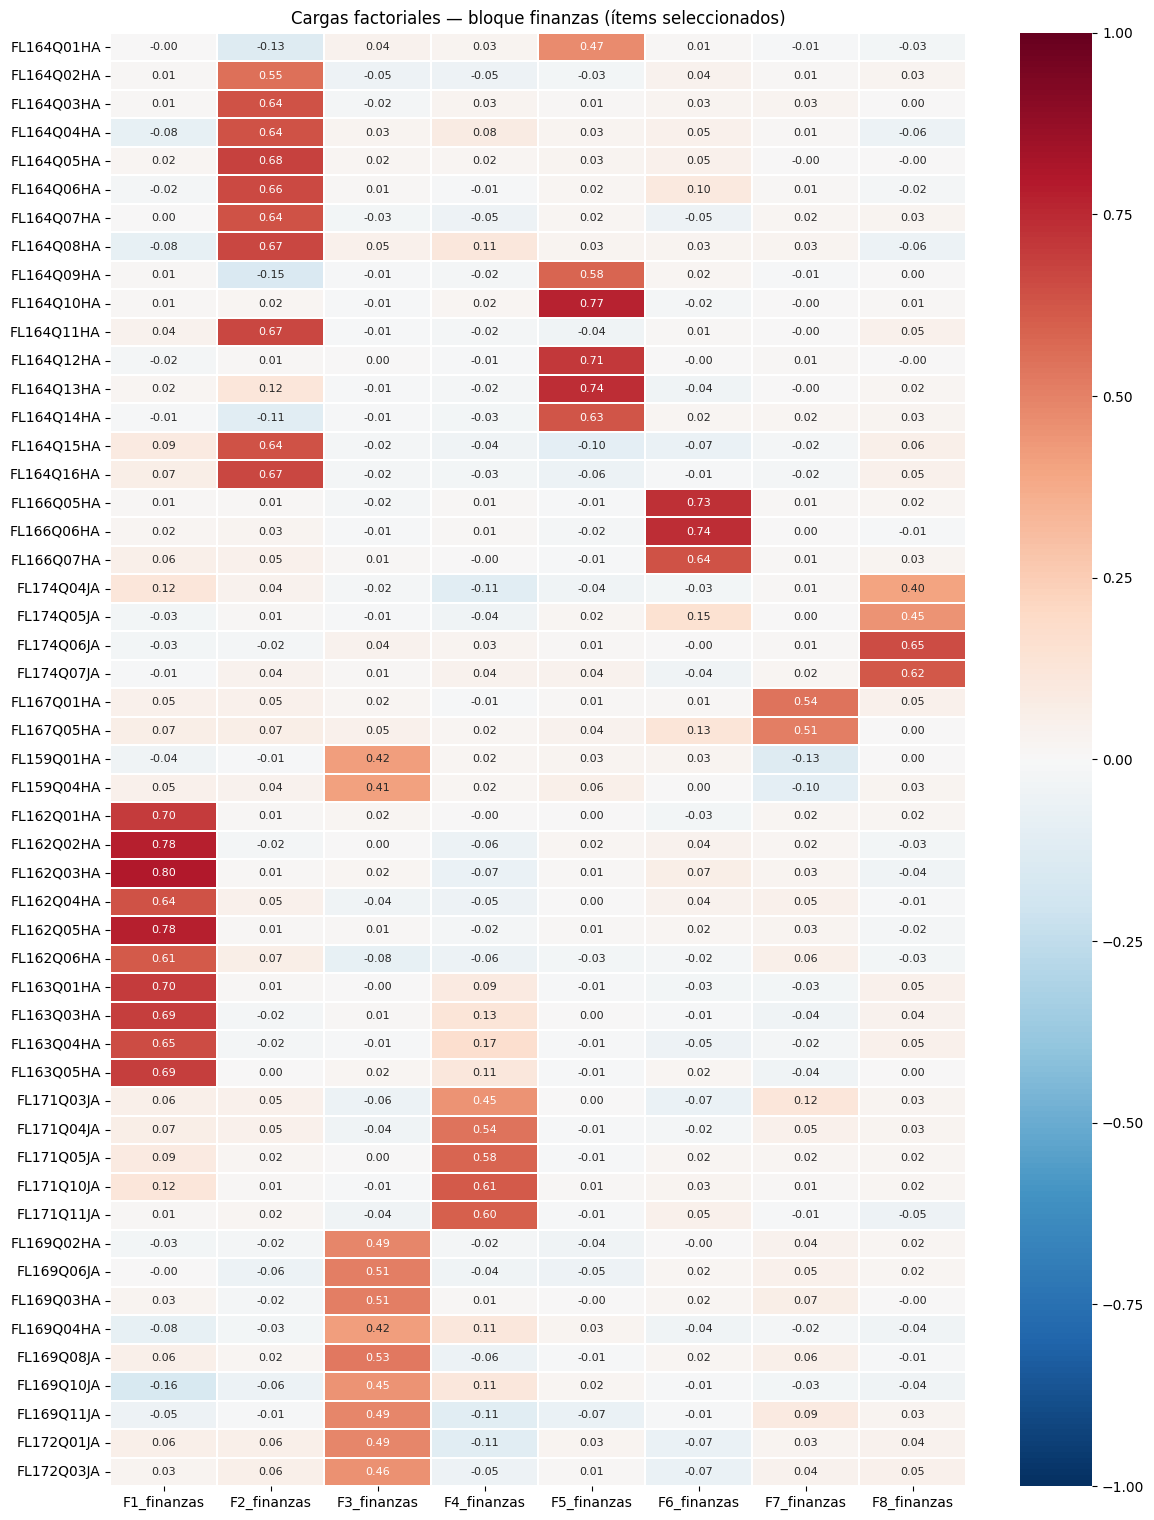


═══════════════════════════════════════════════════════
  BLOQUE: OTROS (43 columnas)
═══════════════════════════════════════════════════════
  KMO          : 0.664  (adecuado)
  Bartlett p   : 0.0000  (significativo ✓)
  Factores seleccionados (eigenvalor > 1): 5


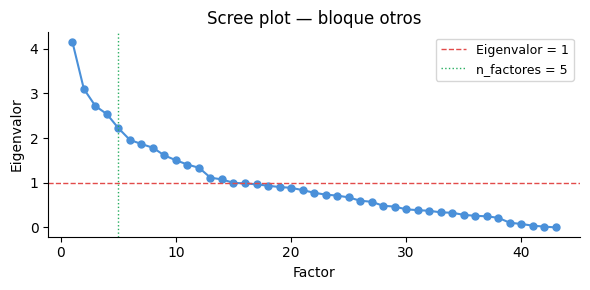

  Ítems con carga ≥ 0.4: 17 / 43


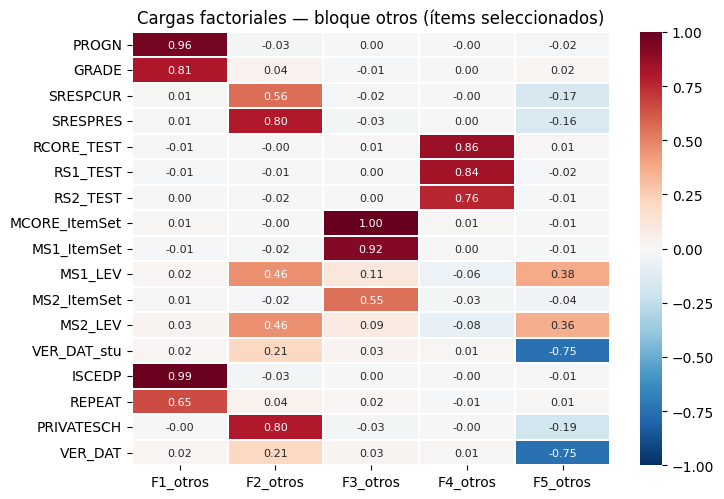

In [44]:
resultados_efa = {}
todos_items_seleccionados = []

BLOQUES_EJECUTAR = ["estudiante", "escuela_a", "escuela_b", "escuela_c",
                    "finanzas", "otros"]

# for nombre_bloque in BLOQUES_PREFIJOS:
for nombre_bloque in BLOQUES_EJECUTAR:
    cols_bloque = [c for c, b in bloque_por_col.items() if b == nombre_bloque]
    if len(cols_bloque) == 0:
        continue

    max_fact = MAX_FACTORES_POR_BLOQUE.get(nombre_bloque, 8)

    df_bloque = df[cols_bloque].copy()
    items, cargas, n_fact = efa_bloque(
        df_bloque,
        nombre_bloque=nombre_bloque,
        umbral_carga=UMBRAL_CARGA,
        max_factores=max_fact
    )

    resultados_efa[nombre_bloque] = {
        "items_seleccionados" : items,
        "cargas"              : cargas,
        "n_factores"          : n_fact,
        "n_columnas_bloque"   : len(cols_bloque),
    }
    todos_items_seleccionados.extend(items)

cols_sin_clasificar = [c for c, b in bloque_por_col.items() if b == "sin_clasificar"]
if cols_sin_clasificar:
    print(f"\n⚠ {len(cols_sin_clasificar)} columnas sin clasificar")
    print("Ejemplos:", cols_sin_clasificar[:10])

Resolviendo problema de poca varianza en escuela

In [45]:
cols_escuela_a = [c for c, b in bloque_por_col.items() if b == "escuela_a"]
print(f"Total columnas escuela_a: {len(cols_escuela_a)}")
print("\nPrimeras 20 columnas:")
print(cols_escuela_a[:20])

Total columnas escuela_a: 99

Primeras 20 columnas:
['SC018Q10JA01', 'SC018Q10JA02', 'SC168Q03JA', 'SC004Q05NA', 'SC001Q01TA', 'SC013Q01TA', 'SC014Q01TA', 'SC011Q01TA', 'SC012Q01TA', 'SC012Q02TA', 'SC012Q03TA', 'SC012Q04TA', 'SC012Q05TA', 'SC012Q06TA', 'SC012Q08JA', 'SC012Q10JA', 'SC012Q11JA', 'SC012Q12JA', 'SC037Q01TA', 'SC037Q02TA']


NO vale la pena recuperar el bloque_a.
SC012 son ítems de evaluación y monitoreo escolar. SC037 es uso de evaluaciones estandarizadas. SC001 es tamaño de comunidad. SC013 y SC014 son tipo y financiamiento de escuela. SC018 y SC168 son recursos físicos y equipamiento. SC011 es competencia entre escuelas.
Estas son variables de estructura y gobernanza escolar — importantes conceptualmente pero que en zona rural tienen poca variabilidad porque la mayoría de escuelas rurales responden de forma muy similar a estas preguntas. Eso explica exactamente el KMO bajo: no hay suficiente varianza compartida porque el contexto rural homogeniza las respuestas.

## 6. Resumen del EFA

In [46]:
print("═" * 60)
print(f"  {'Bloque':<18} {'Cols':>6} {'Factores':>10} {'Seleccionados':>14}")
print("═" * 60)
for bloque, res in resultados_efa.items():
    print(f"  {bloque:<18} {res['n_columnas_bloque']:>6} "
          f"{res['n_factores']:>10} {len(res['items_seleccionados']):>14}")
print("─" * 60)
print(f"  {'TOTAL ítems seleccionados':<40} {len(todos_items_seleccionados):>14}")
print("═" * 60)

════════════════════════════════════════════════════════════
  Bloque               Cols   Factores  Seleccionados
════════════════════════════════════════════════════════════
  estudiante            136         10             47
  escuela_a              99          0              0
  escuela_b              92          6             34
  escuela_c             109          6             49
  finanzas               93          8             51
  otros                  43          5             17
────────────────────────────────────────────────────────────
  TOTAL ítems seleccionados                           198
════════════════════════════════════════════════════════════


Pruebas extra para verificar los agrupamientos

In [47]:
for bloque in ["escuela", "padres", "finanzas", "otros", "sin_clasificar"]:
    cols = [c for c, b in bloque_por_col.items() if b == bloque]
    prefijos_unicos = pd.Series([extraer_prefijo(c, 2) for c in cols]).value_counts()
    print(f"\nBloque '{bloque}' ({len(cols)} cols) — prefijos:")
    print(prefijos_unicos.to_string())


Bloque 'escuela' (0 cols) — prefijos:
Series([], )

Bloque 'padres' (1 cols) — prefijos:
PA    1

Bloque 'finanzas' (93 cols) — prefijos:
FL    93

Bloque 'otros' (43 cols) — prefijos:
RS    4
MS    4
RC    3
MA    3
EF    2
PR    2
CO    2
SR    2
MC    2
VE    2
MI    2
GR    1
RD    1
MP    1
IS    1
LA    1
RE    1
SK    1
TA    1
DU    1
FI    1
HI    1
UN    1
CL    1
CR    1
AB    1

Bloque 'sin_clasificar' (0 cols) — prefijos:
Series([], )


Verificar subgrupos en EScuela

In [48]:
cols_escuela = [c for c, b in bloque_por_col.items() if b == "escuela"]
print(f"Total: {len(cols_escuela)}")
print("\nPrimeras 30 columnas:")
print(cols_escuela[:30])
print("\nÚltimas 20 columnas:")
print(cols_escuela[-20:])

Total: 0

Primeras 30 columnas:
[]

Últimas 20 columnas:
[]


Verificar naturaleza de los items:

In [49]:
# Corre esto para ver la distribución de valores únicos en los 235 ítems seleccionados
df_sel = pd.read_csv("/workspace/data/output_rural/dataset_efa_items_seleccionados.csv")

unicos_por_col = df_sel.nunique()
distribucion = unicos_por_col.value_counts().sort_index()
print("Valores únicos → N° de columnas:")
print(distribucion.to_string())

Valores únicos → N° de columnas:
2     38
3     38
4     91
5     13
6     12
7      3
8      1
9      1
10     1


## 7. Exportar cargas factoriales completas

Útil para la sección de metodología del artículo.

In [50]:
frames_cargas = []
for bloque, res in resultados_efa.items():
    if not res["cargas"].empty:
        df_c = res["cargas"].copy()
        df_c["bloque"] = bloque
        df_c["carga_max"] = df_c.drop(columns="bloque").abs().max(axis=1)
        df_c["seleccionado"] = df_c["carga_max"] >= UMBRAL_CARGA
        frames_cargas.append(df_c)

if frames_cargas:
    df_cargas_global = pd.concat(frames_cargas)
    df_cargas_global.to_csv("/workspace/data/output_rural/efa_cargas_factoriales.csv")
    print("Guardado: efa_cargas_factoriales.csv")

Guardado: efa_cargas_factoriales.csv


## 8. Guardar dataset final para IRT y LCA

In [51]:
# Eliminar duplicados por si un ítem apareció en más de un bloque
items_unicos = list(dict.fromkeys(todos_items_seleccionados))

df_final = df[items_unicos].copy()
df_final.to_csv("/workspace/data/output_rural/dataset_efa_items_seleccionados.csv", index=False)

print(f"Guardado: dataset_efa_items_seleccionados.csv")
print(f"  Filas : {df_final.shape[0]:,}")
print(f"  Ítems : {df_final.shape[1]:,}")
print()
print("Siguiente paso → paso3_irt.ipynb  y  paso3_lca.ipynb")

Guardado: dataset_efa_items_seleccionados.csv
  Filas : 3,720
  Ítems : 198

Siguiente paso → paso3_irt.ipynb  y  paso3_lca.ipynb


Interpretacion de factores latentes:

In [52]:
import pandas as pd
import numpy as np

# Cargar las cargas factoriales guardadas en el Paso 2
df_cargas = pd.read_csv("/workspace/data/output_rural/efa_cargas_factoriales.csv", index_col=0)

print("Columnas disponibles:")
print(df_cargas.columns.tolist())
print(f"\nShape: {df_cargas.shape}")
print(f"\nBloques únicos:")
print(df_cargas["bloque"].value_counts().to_string())

Columnas disponibles:
['F1_estudiante', 'F2_estudiante', 'F3_estudiante', 'F4_estudiante', 'F5_estudiante', 'F6_estudiante', 'F7_estudiante', 'F8_estudiante', 'F9_estudiante', 'F10_estudiante', 'bloque', 'carga_max', 'seleccionado', 'F1_escuela_b', 'F2_escuela_b', 'F3_escuela_b', 'F4_escuela_b', 'F5_escuela_b', 'F6_escuela_b', 'F1_escuela_c', 'F2_escuela_c', 'F3_escuela_c', 'F4_escuela_c', 'F5_escuela_c', 'F6_escuela_c', 'F1_finanzas', 'F2_finanzas', 'F3_finanzas', 'F4_finanzas', 'F5_finanzas', 'F6_finanzas', 'F7_finanzas', 'F8_finanzas', 'F1_otros', 'F2_otros', 'F3_otros', 'F4_otros', 'F5_otros']

Shape: (473, 38)

Bloques únicos:
bloque
estudiante    136
escuela_c     109
finanzas       93
escuela_b      92
otros          43


Top de items por factor de cada bloque de los datos

In [53]:
import pandas as pd
import numpy as np

df_cargas = pd.read_csv("/workspace/data/output_rural/efa_cargas_factoriales.csv", index_col=0)

# Columnas de factores por bloque
FACTORES_POR_BLOQUE = {
    "estudiante" : [f"F{i}_estudiante" for i in range(1, 11)],
    "escuela_a"  : [f"F{i}_escuela_a"  for i in range(1, 7)],
    "escuela_b"  : [f"F{i}_escuela_b"  for i in range(1, 7)],
    "escuela_c"  : [f"F{i}_escuela_c"  for i in range(1, 7)],
    "finanzas"   : [f"F{i}_finanzas"   for i in range(1, 9)],
    "otros"      : [f"F{i}_otros"      for i in range(1, 6)],
}

TOP_N = 8  # ítems con mayor carga por factor

resumen = []

for bloque, factores in FACTORES_POR_BLOQUE.items():
    df_bloque = df_cargas[df_cargas["bloque"] == bloque].copy()

    # Solo ítems seleccionados (carga >= 0.40)
    df_sel = df_bloque[df_bloque["seleccionado"] == True]

    print(f"\n{'═'*65}")
    print(f"  BLOQUE: {bloque.upper()}  ({len(df_sel)} ítems seleccionados)")
    print(f"{'═'*65}")

    for factor in factores:
        if factor not in df_bloque.columns:
            continue

        # Top ítems por carga absoluta en este factor
        cargas_factor = df_bloque[factor].abs().sort_values(ascending=False)
        top_items = cargas_factor.head(TOP_N)

        # Solo mostrar si hay ítems con carga >= 0.35
        if top_items.iloc[0] < 0.35:
            continue

        print(f"\n  {factor}")
        print(f"  {'Ítem':<20} {'Carga':>8}")
        print(f"  {'─'*30}")

        for item, carga_abs in top_items.items():
            carga_real = df_bloque.loc[item, factor]
            if carga_abs >= 0.30:
                print(f"  {item:<20} {carga_real:>8.3f}")

        resumen.append({
            "bloque"  : bloque,
            "factor"  : factor,
            "top_item": top_items.index[0],
            "carga_max": top_items.iloc[0]
        })

# Guardar resumen
pd.DataFrame(resumen).to_csv("/workspace/data/output_rural/efa_resumen_top_items_por_factor.csv", index=False)
print("\n\nGuardado: efa_resumen_top_items_por_factor.csv")


═════════════════════════════════════════════════════════════════
  BLOQUE: ESTUDIANTE  (47 ítems seleccionados)
═════════════════════════════════════════════════════════════════

  F1_estudiante
  Ítem                    Carga
  ──────────────────────────────
  ST254Q06JA              0.647
  ST251Q04JA              0.643
  ST250Q05JA              0.614
  ST251Q03JA              0.610
  ST250Q02JA              0.518
  ST254Q01JA              0.498
  ST250Q04JA             -0.437
  ST259Q01JA              0.429

  F2_estudiante
  Ítem                    Carga
  ──────────────────────────────
  ST268Q08JA              0.873
  ST268Q07JA              0.838
  ST268Q09JA              0.827
  ST268Q06JA             -0.343

  F3_estudiante
  Ítem                    Carga
  ──────────────────────────────
  ST250D07JA              0.828
  ST250D06JA              0.785
  ST251D08JA              0.729
  ST251D09JA              0.714

  F4_estudiante
  Ítem                    Carga
  ───────────